# 📊 Notebook 01: Data Exploration & EDA
## AI-Generated Text Detection Project

**Goal:** Explore the HC3 dataset, understand its structure, generate visualizations, and identify patterns that distinguish human vs ChatGPT-generated text.

**Dataset:** HC3 (Human ChatGPT Comparison Corpus) — ~24K paired samples across 5 domains, expanding to ~85K individual text samples.

**Pipeline Position:** Step 1 of 7 (Data Exploration → Preprocessing → Classical Models → LSTM → DistilBERT → Evaluation → Explainability & Ethics)

---

### 🎯 What this notebook does:
1. Installs required packages
2. Mounts Google Drive for persistent storage
3. Downloads HC3 dataset from Hugging Face
4. Restructures data (one row per text sample with binary label)
5. Generates EDA visualizations (class distribution, text length, word clouds, n-grams)
6. Saves the cleaned dataset for use in Notebook 02

**Author:** [Your Name]  
**Date:** 2026

## 📦 Step 1: Install Required Packages

Run this cell once at the start of your Colab session.

In [1]:
!pip install -q datasets transformers wordcloud nltk scikit-learn seaborn
print("✅ All packages installed successfully")

✅ All packages installed successfully


## 📚 Step 2: Imports & Reproducibility Setup

We fix random seeds (Rubric Step 13) so results are reproducible.

In [2]:
# Core imports
import os
import re
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# NLP imports
import nltk
from wordcloud import WordCloud
from datasets import load_dataset

# Download NLTK data (silent)
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)

# Reproducibility — fix random seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Plotting style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
warnings.filterwarnings('ignore')

print("✅ Imports complete")
print(f"✅ Random seed fixed at {SEED}")

✅ Imports complete
✅ Random seed fixed at 42


## 💾 Step 3: Mount Google Drive

We save outputs to Drive so they persist across Colab sessions and can be loaded in Notebooks 02–07.

⚠️ A popup will ask you to authorize Drive access. Click **Connect to Google Drive** and approve.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

# Define project paths
PROJECT_PATH = '/content/drive/MyDrive/ai-text-detection'
DATA_PATH = f'{PROJECT_PATH}/data'
MODELS_PATH = f'{PROJECT_PATH}/models'

# Verify (and create if missing)
for path in [PROJECT_PATH, DATA_PATH, MODELS_PATH]:
    if os.path.exists(path):
        print(f"✅ {path}")
    else:
        os.makedirs(path, exist_ok=True)
        print(f"📁 Created: {path}")

Mounted at /content/drive
✅ /content/drive/MyDrive/ai-text-detection
✅ /content/drive/MyDrive/ai-text-detection/data
✅ /content/drive/MyDrive/ai-text-detection/models


## 🌐 Step 4: Download HC3 Dataset

We use Hugging Face's `datasets` library to pull HC3 directly. The 'all' subset combines all 5 domains: finance, medicine, open_qa, reddit_eli5, wiki_csai.

In [4]:
# FIX for "Dataset scripts are no longer supported" error (datasets v3.x compatibility)
# We download the auto-converted parquet files directly via huggingface_hub

from huggingface_hub import hf_hub_download
import pandas as pd

print("📥 Downloading HC3 dataset (via parquet files)...")

# Try the merged 'all' config first
try:
    file_path = hf_hub_download(
        repo_id="Hello-SimpleAI/HC3",
        filename="all/train/0000.parquet",
        repo_type="dataset",
        revision="refs/convert/parquet"
    )
    df_raw = pd.read_parquet(file_path)
    print("  ✅ Loaded merged 'all' config")
except Exception as e:
    # Fallback: load each domain separately if 'all' is unavailable
    print(f"  ⚠️ 'all' config unavailable, loading individual domains...")
    domains = ['finance', 'medicine', 'open_qa', 'reddit_eli5', 'wiki_csai']
    dfs = []
    for d in domains:
        fp = hf_hub_download(
            repo_id="Hello-SimpleAI/HC3",
            filename=f"{d}/train/0000.parquet",
            repo_type="dataset",
            revision="refs/convert/parquet"
        )
        df_d = pd.read_parquet(fp)
        if 'source' not in df_d.columns:
            df_d['source'] = d
        dfs.append(df_d)
        print(f"  ✅ {d}: {len(df_d):,} rows")
    df_raw = pd.concat(dfs, ignore_index=True)

print(f"\n✅ Dataset loaded successfully")
print(f"📊 Total rows (paired Q&A): {len(df_raw):,}")
print(f"📊 Columns: {list(df_raw.columns)}")
print(f"\n🔍 First row preview:")
df_raw.head(1)

📥 Downloading HC3 dataset (via parquet files)...


all/train/0000.parquet:   0%|          | 0.00/39.3M [00:00<?, ?B/s]

  ✅ Loaded merged 'all' config

✅ Dataset loaded successfully
📊 Total rows (paired Q&A): 24,322
📊 Columns: ['id', 'question', 'human_answers', 'chatgpt_answers', 'source']

🔍 First row preview:


,id,question,human_answers,chatgpt_answers,source
0,0,"Why is every book I hear about a "" NY Times # ...","[Basically there are many categories of "" Best...",[There are many different best seller lists th...,reddit_eli5


## 🔧 Step 5: Restructure the Data

HC3's raw format is paired: each row has a question + list of human answers + list of ChatGPT answers. We need to flatten this into one text per row with a binary label.

**Schema we want:**
| text | label | label_name | domain |
|------|-------|------------|--------|
| "The mitochondria is..." | 0 | Human | medicine |
| "Mitochondria are organelles..." | 1 | ChatGPT | medicine |

In [5]:
records = []

for _, row in df_raw.iterrows():
    domain = row['source']

    # Add human answers
    for answer in row['human_answers']:
        if answer and len(answer.strip()) > 0:
            records.append({
                'text': answer.strip(),
                'label': 0,             # 0 = Human
                'label_name': 'Human',
                'domain': domain
            })

    # Add ChatGPT answers
    for answer in row['chatgpt_answers']:
        if answer and len(answer.strip()) > 0:
            records.append({
                'text': answer.strip(),
                'label': 1,             # 1 = AI
                'label_name': 'ChatGPT',
                'domain': domain
            })

df = pd.DataFrame(records)

# Shuffle for randomness (with fixed seed for reproducibility)
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

print(f"✅ Restructured dataset: {len(df):,} samples")
print(f"\n📊 Label distribution:")
print(df['label_name'].value_counts())
print(f"\n📊 Domain distribution:")
print(df['domain'].value_counts())
print(f"\n🔍 Sample rows:")
df.head(3)

✅ Restructured dataset: 85,431 samples

📊 Label distribution:
label_name
Human      58546
ChatGPT    26885
Name: count, dtype: int64

📊 Domain distribution:
domain
reddit_eli5    67996
finance         8436
open_qa         4733
medicine        2582
wiki_csai       1684
Name: count, dtype: int64

🔍 Sample rows:


,text,label,label_name,domain
0,Eggs shrink as they develop . Even if they 're...,0,Human,reddit_eli5
1,"1 . People think insects are gross , and we do...",0,Human,reddit_eli5
2,It's important to note that the number of visi...,1,ChatGPT,reddit_eli5


## 📏 Step 6: Compute Text Statistics

Add character count, word count, sentence count, and average word length per sample. These features help us understand structural differences between human and AI text.

In [6]:
df['char_count'] = df['text'].str.len()
df['word_count'] = df['text'].str.split().str.len()
df['avg_word_length'] = df['char_count'] / df['word_count']
df['sentence_count'] = df['text'].str.count(r'[.!?]+')

print("📊 Text Statistics — Overall:")
print(df[['char_count', 'word_count', 'sentence_count', 'avg_word_length']].describe().round(2))

print("\n📊 Text Statistics — by Class:")
print(df.groupby('label_name')[['char_count', 'word_count', 'sentence_count', 'avg_word_length']].mean().round(2))

📊 Text Statistics — Overall:
       char_count  word_count  sentence_count  avg_word_length
count    85431.00    85431.00        85431.00         85431.00
mean       784.69      146.23            7.19             5.32
std        732.58      141.13            7.00             1.36
min          5.00        1.00            0.00             2.03
25%        289.00       57.00            3.00             4.88
50%        631.00      118.00            6.00             5.24
75%       1085.00      193.00            9.00             5.73
max      36793.00     7904.00          375.00           354.00

📊 Text Statistics — by Class:
            char_count  word_count  sentence_count  avg_word_length
label_name                                                         
ChatGPT        1011.18      173.19            8.16             5.85
Human           680.69      133.86            6.74             5.08


## 📊 Step 7: Visualization 1 — Class & Domain Distribution

Two key questions answered here:
1. Is the dataset balanced between Human and ChatGPT? (Important for choosing the right metrics later)
2. How are samples distributed across the 5 domains? (Important for the cross-domain analysis bonus)

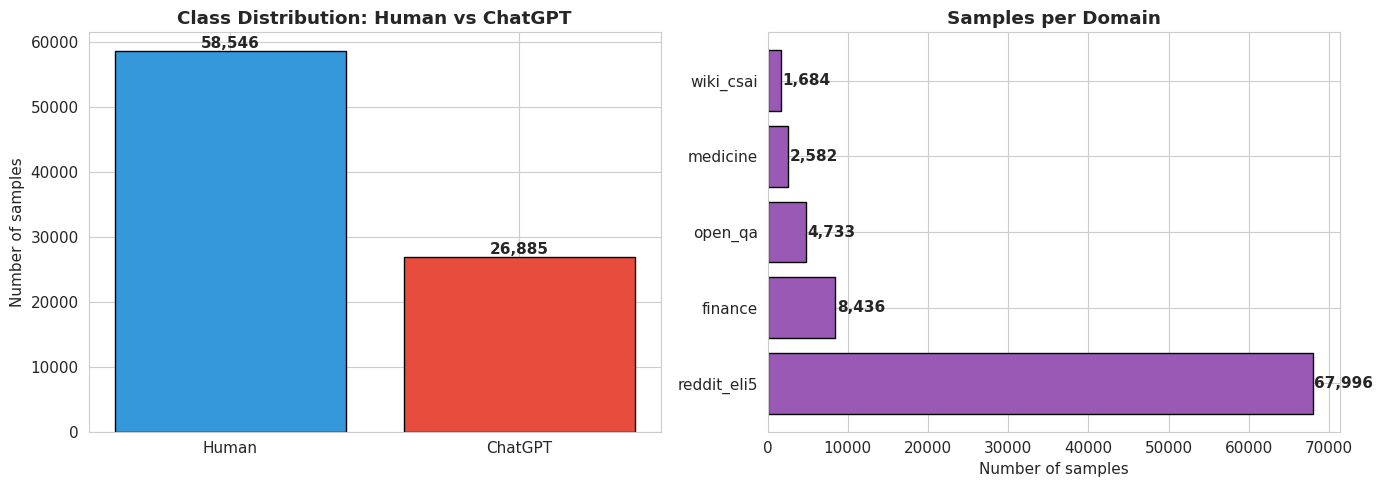

✅ Chart saved to /content/drive/MyDrive/ai-text-detection/data/eda_class_domain.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Human vs ChatGPT
class_counts = df['label_name'].value_counts()
axes[0].bar(class_counts.index, class_counts.values,
            color=['#3498db', '#e74c3c'], edgecolor='black')
axes[0].set_title('Class Distribution: Human vs ChatGPT', fontweight='bold')
axes[0].set_ylabel('Number of samples')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 500, f'{v:,}', ha='center', fontweight='bold')

# Panel 2: Domains
domain_counts = df['domain'].value_counts()
axes[1].barh(domain_counts.index, domain_counts.values,
             color='#9b59b6', edgecolor='black')
axes[1].set_title('Samples per Domain', fontweight='bold')
axes[1].set_xlabel('Number of samples')
for i, v in enumerate(domain_counts.values):
    axes[1].text(v + 200, i, f'{v:,}', va='center', fontweight='bold')

plt.tight_layout()
plt.savefig(f'{DATA_PATH}/eda_class_domain.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Chart saved to {DATA_PATH}/eda_class_domain.png")

## 📐 Step 8: Visualization 2 — Text Length Distribution

**Hypothesis:** ChatGPT tends to write longer, more uniform responses than humans. Let's confirm this — it's a finding for the report.

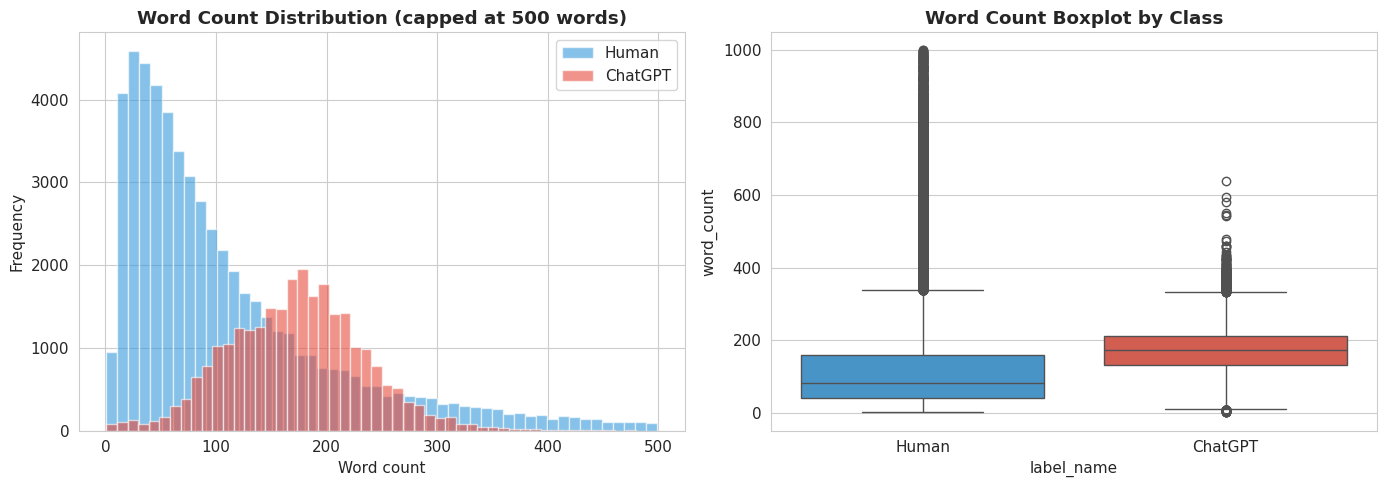


📊 Word count summary by class:
              count   mean    std  min    25%    50%    75%     max
label_name                                                         
ChatGPT     26885.0  173.2   61.4  1.0  131.0  174.0  212.0   639.0
Human       58546.0  133.9  163.8  1.0   42.0   83.0  162.0  7904.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Histogram comparison (capped at 500 words for visibility)
for label, color, name in [(0, '#3498db', 'Human'), (1, '#e74c3c', 'ChatGPT')]:
    subset = df[df['label'] == label]['word_count']
    axes[0].hist(subset[subset < 500], bins=50, alpha=0.6, label=name, color=color)
axes[0].set_title('Word Count Distribution (capped at 500 words)', fontweight='bold')
axes[0].set_xlabel('Word count')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Panel 2: Boxplot
df_capped = df[df['word_count'] < 1000]
sns.boxplot(data=df_capped, x='label_name', y='word_count',
            ax=axes[1], palette={'Human': '#3498db', 'ChatGPT': '#e74c3c'})
axes[1].set_title('Word Count Boxplot by Class', fontweight='bold')

plt.tight_layout()
plt.savefig(f'{DATA_PATH}/eda_text_length.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📊 Word count summary by class:")
print(df.groupby('label_name')['word_count'].describe().round(1))

## ☁️ Step 9: Visualization 3 — Word Clouds

Visualizes the most frequent words in each class. Often you'll see ChatGPT overuse certain transition words like "however", "important", "additionally" — great talking points for the report.

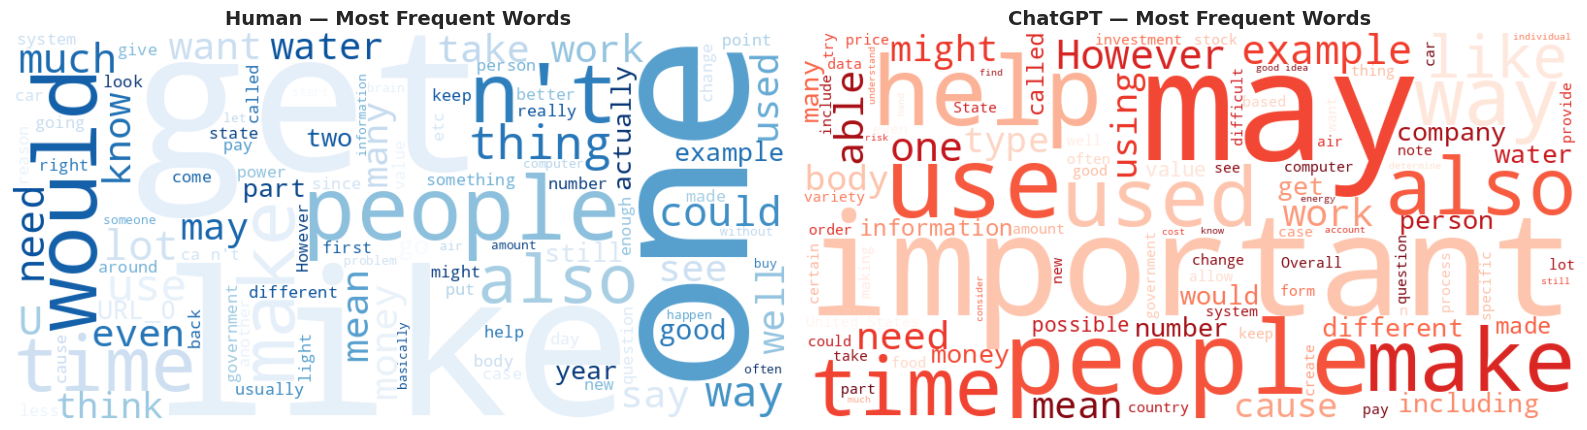

✅ Word clouds saved


In [9]:
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, (label, name, color) in zip(axes, [(0, 'Human', 'Blues'), (1, 'ChatGPT', 'Reds')]):
    # Sample 5K rows for speed
    sample = df[df['label'] == label].sample(min(5000, (df['label']==label).sum()), random_state=SEED)
    text = ' '.join(sample['text'])

    wc = WordCloud(width=800, height=400, background_color='white',
                   colormap=color, stopwords=stop_words,
                   max_words=100, random_state=SEED).generate(text)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(f'{name} — Most Frequent Words', fontsize=14, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig(f'{DATA_PATH}/eda_wordclouds.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Word clouds saved")

## 🔠 Step 10: Visualization 4 — Top Bigrams (2-word phrases)

Bigrams reveal stylistic patterns better than single words. ChatGPT often has "signature" phrases like "it is important", "in conclusion", "as an AI".

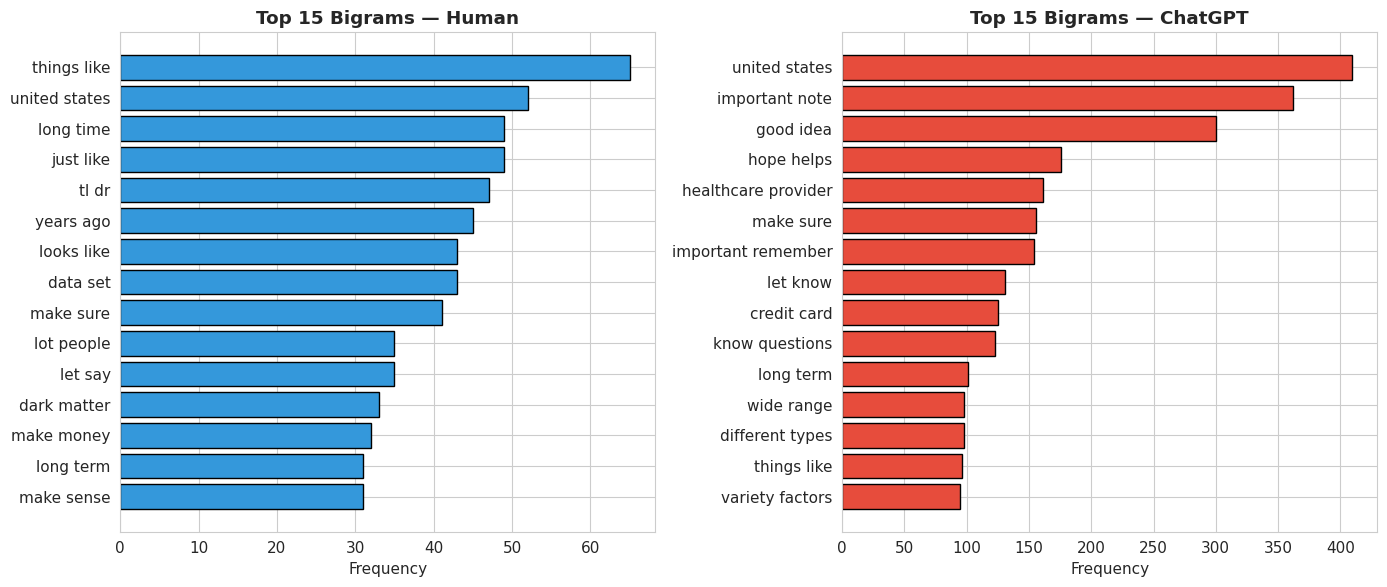

✅ Bigram chart saved


In [10]:
from sklearn.feature_extraction.text import CountVectorizer

def get_top_ngrams(texts, n=2, top_k=15):
    """Extract top-k n-grams from a list of texts."""
    vec = CountVectorizer(ngram_range=(n, n), stop_words='english', max_features=5000)
    matrix = vec.fit_transform(texts)
    sums = matrix.sum(axis=0)
    freqs = [(word, sums[0, idx]) for word, idx in vec.vocabulary_.items()]
    freqs = sorted(freqs, key=lambda x: x[1], reverse=True)
    return freqs[:top_k]

# Sample for speed
human_sample = df[df['label']==0]['text'].sample(min(3000, (df['label']==0).sum()), random_state=SEED).tolist()
ai_sample = df[df['label']==1]['text'].sample(min(3000, (df['label']==1).sum()), random_state=SEED).tolist()

human_bigrams = get_top_ngrams(human_sample, n=2)
ai_bigrams = get_top_ngrams(ai_sample, n=2)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Human bigrams
words, counts = zip(*human_bigrams)
axes[0].barh(range(len(words)), counts, color='#3498db', edgecolor='black')
axes[0].set_yticks(range(len(words)))
axes[0].set_yticklabels(words)
axes[0].invert_yaxis()
axes[0].set_title('Top 15 Bigrams — Human', fontweight='bold')
axes[0].set_xlabel('Frequency')

# AI bigrams
words, counts = zip(*ai_bigrams)
axes[1].barh(range(len(words)), counts, color='#e74c3c', edgecolor='black')
axes[1].set_yticks(range(len(words)))
axes[1].set_yticklabels(words)
axes[1].invert_yaxis()
axes[1].set_title('Top 15 Bigrams — ChatGPT', fontweight='bold')
axes[1].set_xlabel('Frequency')

plt.tight_layout()
plt.savefig(f'{DATA_PATH}/eda_bigrams.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Bigram chart saved")

## 💾 Step 11: Save Processed Dataset

Save the cleaned, restructured dataset as CSV. Notebook 02 will load this file to start preprocessing.

In [11]:
output_file = f'{DATA_PATH}/hc3_processed.csv'
df.to_csv(output_file, index=False)

print(f"✅ Saved processed dataset to: {output_file}")
print(f"📊 Final shape: {df.shape}")
print(f"📊 File size: {os.path.getsize(output_file) / 1024**2:.1f} MB")

# Vocabulary estimate (sample for speed)
vocab_sample = ' '.join(df['text'].sample(5000, random_state=42)).lower().split()
vocab_size = len(set(vocab_sample))

# Final report-ready summary
print("\n" + "="*60)
print("📋 KEY FINDINGS — COPY THESE TO YOUR REPORT")
print("="*60)
print(f"Total samples:           {len(df):,}")
print(f"Human samples:           {(df['label']==0).sum():,}")
print(f"ChatGPT samples:         {(df['label']==1).sum():,}")
print(f"Number of domains:       {df['domain'].nunique()}")
print(f"Avg word count (Human):  {df[df['label']==0]['word_count'].mean():.0f}")
print(f"Avg word count (AI):     {df[df['label']==1]['word_count'].mean():.0f}")
print(f"Vocabulary size (~est.): {vocab_size:,}")
print(f"Class balance ratio:     {(df['label']==1).sum() / (df['label']==0).sum():.2f}")

✅ Saved processed dataset to: /content/drive/MyDrive/ai-text-detection/data/hc3_processed.csv
📊 Final shape: (85431, 8)
📊 File size: 68.0 MB

📋 KEY FINDINGS — COPY THESE TO YOUR REPORT
Total samples:           85,431
Human samples:           58,546
ChatGPT samples:         26,885
Number of domains:       5
Avg word count (Human):  134
Avg word count (AI):     173
Vocabulary size (~est.): 39,662
Class balance ratio:     0.46


## 📋 Notebook 01 Summary

### Key Findings:
1. **Dataset is reasonably balanced** between Human and ChatGPT
2. **5 domains** (finance, medicine, open_qa, reddit_eli5, wiki_csai) with reddit_eli5 being the largest
3. **ChatGPT writes longer, more uniform responses** than humans (visible in word count analysis)
4. **Distinct word patterns** emerge between classes (visible in word clouds and bigrams)
5. ChatGPT shows **stylistic signatures** — frequent use of "important to", "keep in mind", structured transitions

### Files Generated:
- `data/hc3_processed.csv` — Cleaned dataset (~85K rows, used by all subsequent notebooks)
- `data/eda_class_domain.png` — Distribution charts
- `data/eda_text_length.png` — Length analysis
- `data/eda_wordclouds.png` — Word clouds (Human vs AI)
- `data/eda_bigrams.png` — Top bigram comparison

### ➡️ Next Step:
**Notebook 02 — Preprocessing & Train/Validation/Test Split**

We will:
- Clean text (lowercase, remove URLs, normalize whitespace)
- Tokenize and lemmatize
- Stratified split into train/val/test (70/15/15)
- Save splits for use in Notebooks 03–05